### Celda 1: configuración y funciones

In [4]:
from pynq import Overlay, allocate
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import time

In [5]:
ol  = Overlay("sobel_p.bit")
dma = ol.axi_dma_0

PAD = 3   # padding words: the hardware output is delayed by W/8 + 3 words

In [6]:
def load_gray(path):
    g = np.array(Image.open(path).convert("L"))
    return g[:, :g.shape[1] // 8 * 8]          # width must be a multiple of 8

def zero_borders(a):
    a[0, :] = 0; a[-1, :] = 0; a[:, 0] = 0; a[:, -1] = 0

def sobel_ps(g, out):
    """Software reference: |Gx| + |Gy| saturated to 255, borders = 0."""
    p = g.astype(np.int16)
    gx = (p[:-2, 2:] + 2*p[1:-1, 2:] + p[2:, 2:]) - (p[:-2, :-2] + 2*p[1:-1, :-2] + p[2:, :-2])
    gy = (p[2:, :-2] + 2*p[2:, 1:-1] + p[2:, 2:]) - (p[:-2, :-2] + 2*p[:-2, 1:-1] + p[:-2, 2:])
    np.minimum(np.abs(gx) + np.abs(gy), 255, out=gx)
    out[1:-1, 1:-1] = gx
    zero_borders(out)

def make_buffers(h, w):
    """DMA buffers: [header][image H*W bytes][PAD padding words]."""
    n = 8 + h * w + 8 * PAD
    ib = allocate(shape=(n,), dtype=np.uint8)
    ob = allocate(shape=(n,), dtype=np.uint8)
    ib[:8].view(np.uint64)[0] = w // 8         # header: words per row
    ib[8 + h * w:] = 0                         # padding words
    return ib, ob

def load_image(ib, g):
    h, w = g.shape
    ib[8:8 + h * w] = g.ravel()

def run_pl(ib, ob):
    """Returns (flush, dma, invalidate) times in seconds."""
    t0 = time.perf_counter(); ib.flush()
    t1 = time.perf_counter()
    dma.recvchannel.transfer(ob)
    dma.sendchannel.transfer(ib)
    dma.sendchannel.wait(); dma.recvchannel.wait()
    t2 = time.perf_counter(); ob.invalidate()
    t3 = time.perf_counter()
    return t1 - t0, t2 - t1, t3 - t2

def unpack_pl(ob, h, w):
    """Removes the header and the pipeline delay, returns an HxW image."""
    assert ob[:8].view(np.uint64)[0] == w // 8, "header mismatch"
    d = w + 8 * PAD                            # delay in pixels
    res = np.zeros((h, w), dtype=np.uint8)
    res[:h - 1] = ob[8 + d: 8 + d + (h - 1) * w].reshape(h - 1, w)
    zero_borders(res)
    return res

### Celda 2: prueba visual con colors.jpg

800x600  ¿PL igual a PS?: True


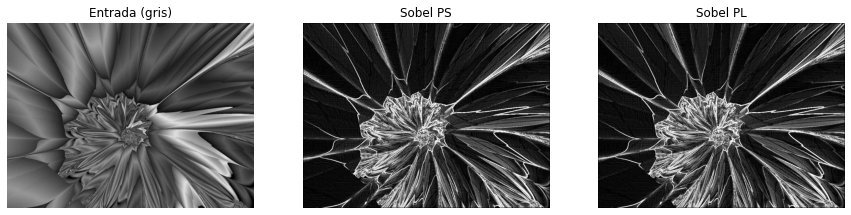

In [7]:
g = load_gray("colors.jpg")
h, w = g.shape
ib, ob = make_buffers(h, w)
load_image(ib, g)

res_ps = np.empty_like(g); sobel_ps(g, res_ps)
run_pl(ib, ob)
res_pl = unpack_pl(ob, h, w)
print(f"{w}x{h}  ¿PL igual a PS?: {np.array_equal(res_pl, res_ps)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [g, res_ps, res_pl], ["Entrada (gris)", "Sobel PS", "Sobel PL"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.show()
ib.freebuffer(); ob.freebuffer()

### Analisis de los resultados

comparación            max |err|     MAE pix != (%) PSNR (dB)
PL vs PS                     0.0    0.00       0.00       inf
PS vs ideal (float)         74.4    9.64      89.20     24.11
PL vs ideal (float)         74.4    9.64      89.20     24.11
Píxeles saturados en 255: 4.44 %


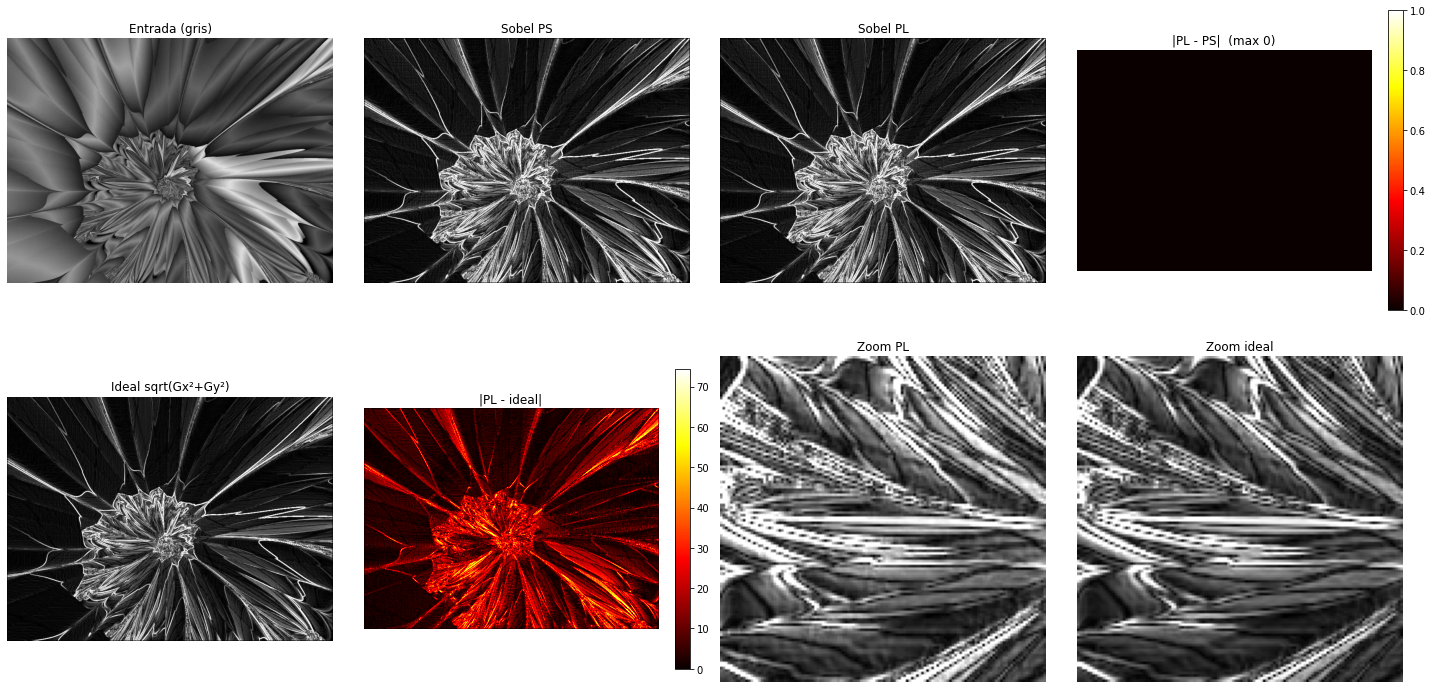

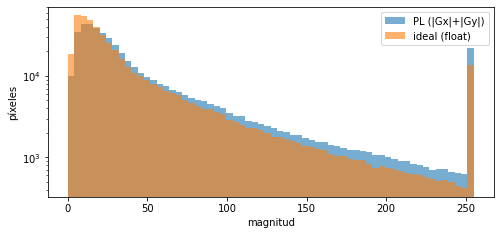

In [8]:
# --- Ideal Sobel in floating point: sqrt(Gx^2 + Gy^2), no saturation ---
p  = g.astype(np.float32)
gx = (p[:-2, 2:] + 2*p[1:-1, 2:] + p[2:, 2:]) - (p[:-2, :-2] + 2*p[1:-1, :-2] + p[2:, :-2])
gy = (p[2:, :-2] + 2*p[2:, 1:-1] + p[2:, 2:]) - (p[:-2, :-2] + 2*p[:-2, 1:-1] + p[:-2, 2:])
ideal = np.zeros(g.shape, np.float32)
ideal[1:-1, 1:-1] = np.sqrt(gx**2 + gy**2)
ideal_8 = np.clip(ideal, 0, 255)                     # same 0..255 range as the outputs

def metrics(a, b):
    """Error metrics of image a against reference b (interior pixels only)."""
    a = a[1:-1, 1:-1].astype(np.float64); b = b[1:-1, 1:-1].astype(np.float64)
    e = a - b
    mse = np.mean(e**2)
    return {"max |err|": np.max(np.abs(e)),
            "MAE": np.mean(np.abs(e)),
            "pix != (%)": 100 * np.mean(e != 0),
            "PSNR (dB)": np.inf if mse == 0 else 10 * np.log10(255**2 / mse)}

print(f"{'comparación':<22} {'max |err|':>9} {'MAE':>7} {'pix != (%)':>10} {'PSNR (dB)':>9}")
for name, a, b in [("PL vs PS", res_pl, res_ps),
                   ("PS vs ideal (float)", res_ps, ideal_8),
                   ("PL vs ideal (float)", res_pl, ideal_8)]:
    m = metrics(a, b)
    print(f"{name:<22} {m['max |err|']:9.1f} {m['MAE']:7.2f} {m['pix != (%)']:10.2f} {m['PSNR (dB)']:9.2f}")

sat = 100 * np.mean(res_pl[1:-1, 1:-1] == 255)
print(f"Píxeles saturados en 255: {sat:.2f} %")

# --- Figure ---
diff_pl_ps = np.abs(res_pl.astype(np.int16) - res_ps.astype(np.int16))
diff_ideal = np.abs(res_pl.astype(np.float32) - ideal_8)

# Zoom: 128x128 crop around the strongest edge region
y0 = np.clip(np.argmax(res_pl.sum(axis=1)) - 64, 0, g.shape[0] - 128)
x0 = np.clip(np.argmax(res_pl.sum(axis=0)) - 64, 0, g.shape[1] - 128)
crop = (slice(y0, y0 + 128), slice(x0, x0 + 128))

fig, ax = plt.subplots(2, 4, figsize=(20, 10))
panels = [
    (g,           "Entrada (gris)",               "gray",    255),
    (res_ps,      "Sobel PS",                     "gray",    255),
    (res_pl,      "Sobel PL",                     "gray",    255),
    (diff_pl_ps,  f"|PL - PS|  (max {diff_pl_ps.max()})", "hot", max(1, diff_pl_ps.max())),
    (ideal_8,     "Ideal sqrt(Gx²+Gy²)",          "gray",    255),
    (diff_ideal,  "|PL - ideal|",                 "hot",     diff_ideal.max()),
    (res_pl[crop], "Zoom PL",                     "gray",    255),
    (ideal_8[crop], "Zoom ideal",                 "gray",    255),
]
for a, (im, title, cmap, vmax) in zip(ax.ravel(), panels):
    h_ = a.imshow(im, cmap=cmap, vmin=0, vmax=vmax); a.set_title(title); a.axis("off")
    if cmap == "hot":
        fig.colorbar(h_, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

# --- Histogram of the edge magnitude ---
plt.figure(figsize=(8, 3.5))
plt.hist(res_pl[1:-1, 1:-1].ravel(), bins=64, range=(0, 255), alpha=0.6, label="PL (|Gx|+|Gy|)")
plt.hist(ideal_8[1:-1, 1:-1].ravel(), bins=64, range=(0, 255), alpha=0.6, label="ideal (float)")
plt.yscale("log"); plt.xlabel("magnitud"); plt.ylabel("píxeles"); plt.legend(); plt.show()

### Celda 3: benchmark por tamaño

In [9]:
def bench(hh, ww, reps=10):
    g = np.random.randint(0, 256, (hh, ww), dtype=np.uint8)   # normal (cached) memory
    ib, ob = make_buffers(hh, ww)
    load_image(ib, g)                                         # outside the timer
    out = np.empty_like(g)

    t = {k: [] for k in ("ps", "flush", "dma", "inval")}
    for _ in range(reps):
        t0 = time.perf_counter(); sobel_ps(g, out); t["ps"].append(time.perf_counter() - t0)
        f, d, i = run_pl(ib, ob)
        t["flush"].append(f); t["dma"].append(d); t["inval"].append(i)

    ok = np.array_equal(unpack_pl(ob, hh, ww), out)
    ib.freebuffer(); ob.freebuffer()
    return {k: np.median(v) * 1e3 for k, v in t.items()}, ok

In [10]:
sizes = [(480, 640), (1080, 1920), (2160, 3840), (3000, 4000)]
print(f"{'tamaño':>11} {'MB':>5} | {'PS':>8} | {'flush':>6} {'DMA':>6} {'inval':>6} {'PL':>7} | {'x total':>7} {'x DMA':>6} | ok")
for hh, ww in sizes:
    r, ok = bench(hh, ww)
    pl = r["flush"] + r["dma"] + r["inval"]
    print(f"{ww:5d}x{hh:<5d} {hh*ww/1e6:5.1f} | {r['ps']:8.2f} | {r['flush']:6.2f} {r['dma']:6.2f} "
          f"{r['inval']:6.2f} {pl:7.2f} | {r['ps']/pl:7.2f} {r['ps']/r['dma']:6.2f} | {ok}")

     tamaño    MB |       PS |  flush    DMA  inval      PL | x total  x DMA | ok
  640x480     0.3 |   118.71 |   0.30   1.29   0.14    1.73 |   68.67  91.99 | True
 1920x1080    2.1 |   798.74 |   0.31   3.48   0.14    3.92 |  203.51 229.78 | True
 3840x2160    8.3 |  3185.71 |   0.34  11.31   0.14   11.79 |  270.27 281.79 | True
 4000x3000   12.0 |  4605.79 |   0.35  15.94   0.14   16.43 |  280.35 288.97 | True


### Comparacion con OpenCV

OpenCV 4.5.4, threads = 2
     tamaño    MP |   OpenCV |      PL     DMA | x total  x DMA | ok
  640x480     0.3 |    66.86 |    1.67    1.25 |   39.98  53.61 | True
 1920x1080    2.1 |   461.41 |    3.92    3.47 |  117.73 132.89 | True
 3840x2160    8.3 |  1855.63 |   11.78   11.30 |  157.46 164.15 | True
 4000x3000   12.0 |  2718.79 |   16.45   15.96 |  165.28 170.35 | True


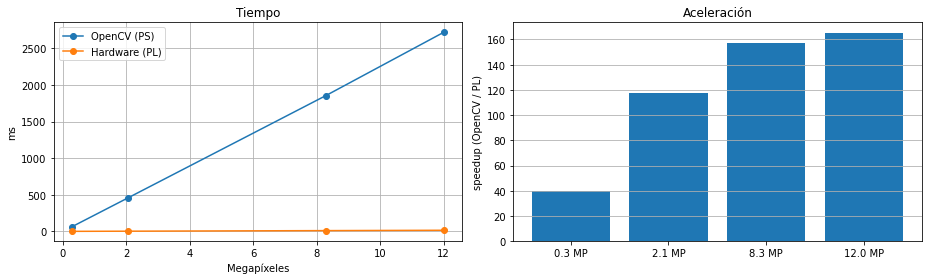

In [11]:
import cv2

def sobel_cv(g, out):
    """OpenCV reference (C++/NEON): |Gx| + |Gy| saturated to 255, borders = 0."""
    gx = cv2.Sobel(g, cv2.CV_16S, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_16S, 0, 1, ksize=3)
    cv2.add(cv2.convertScaleAbs(gx), cv2.convertScaleAbs(gy), dst=out)
    zero_borders(out)                      # OpenCV handles borders differently

def bench_cv(hh, ww, reps=10):
    g = np.random.randint(0, 256, (hh, ww), dtype=np.uint8)   # normal (cached) memory
    ib, ob = make_buffers(hh, ww)
    load_image(ib, g)                                         # outside the timer
    out_cv = np.empty_like(g)

    t_cv, t_pl, t_dma = [], [], []
    for _ in range(reps):
        t0 = time.perf_counter(); sobel_cv(g, out_cv); t_cv.append(time.perf_counter() - t0)
        f, d, i = run_pl(ib, ob)
        t_pl.append(f + d + i); t_dma.append(d)

    ok = np.array_equal(unpack_pl(ob, hh, ww), out_cv)       # bit-exact check
    ib.freebuffer(); ob.freebuffer()
    return np.median(t_cv) * 1e3, np.median(t_pl) * 1e3, np.median(t_dma) * 1e3, ok

print(f"OpenCV {cv2.__version__}, threads = {cv2.getNumThreads()}")
sizes = [(480, 640), (1080, 1920), (2160, 3840), (3000, 4000)]
rows = []
print(f"{'tamaño':>11} {'MP':>5} | {'OpenCV':>8} | {'PL':>7} {'DMA':>7} | {'x total':>7} {'x DMA':>6} | ok")
for hh, ww in sizes:
    cv_ms, pl_ms, dma_ms, ok = bench_cv(hh, ww)
    rows.append((hh * ww / 1e6, cv_ms, pl_ms))
    print(f"{ww:5d}x{hh:<5d} {hh*ww/1e6:5.1f} | {cv_ms:8.2f} | {pl_ms:7.2f} {dma_ms:7.2f} | "
          f"{cv_ms/pl_ms:7.2f} {cv_ms/dma_ms:6.2f} | {ok}")

mp, cv_t, pl_t = map(np.array, zip(*rows))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(mp, cv_t, "o-", label="OpenCV (PS)")
ax[0].plot(mp, pl_t, "o-", label="Hardware (PL)")
ax[0].set_xlabel("Megapíxeles"); ax[0].set_ylabel("ms"); ax[0].set_title("Tiempo"); ax[0].legend(); ax[0].grid(True)
ax[1].bar([f"{m:.1f} MP" for m in mp], cv_t / pl_t)
ax[1].set_ylabel("speedup (OpenCV / PL)"); ax[1].set_title("Aceleración"); ax[1].grid(True, axis="y")
plt.tight_layout(); plt.show()

In [12]:
print("useOptimized:", cv2.useOptimized())
for line in cv2.getBuildInformation().splitlines():
    if any(k in line for k in ("NEON", "CPU/HW features", "Baseline", "Dispatched", "Parallel framework")):
        print(line.strip())

# Time each step on 4000x3000
g = np.random.randint(0, 256, (3000, 4000), dtype=np.uint8)
def t(f, n=5):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return np.median(ts) * 1e3
gx = cv2.Sobel(g, cv2.CV_16S, 1, 0, ksize=3)
ax_ = cv2.convertScaleAbs(gx)
print(f"Sobel x          : {t(lambda: cv2.Sobel(g, cv2.CV_16S, 1, 0, ksize=3)):8.1f} ms")
print(f"convertScaleAbs  : {t(lambda: cv2.convertScaleAbs(gx)):8.1f} ms")
print(f"add              : {t(lambda: cv2.add(ax_, ax_)):8.1f} ms")
cv2.setNumThreads(1)
print(f"Sobel x (1 hilo) : {t(lambda: cv2.Sobel(g, cv2.CV_16S, 1, 0, ksize=3)):8.1f} ms")
cv2.setNumThreads(2)

useOptimized: True
CPU/HW features:
Baseline:
Parallel framework:            TBB (ver 2021.5 interface 12050)
Sobel x          :    488.7 ms
convertScaleAbs  :    799.7 ms
add              :    160.1 ms
Sobel x (1 hilo) :    489.2 ms
